# ICA of the two-threshold response: choice of the FastICA contrast

Fig. S1 projects the (t_A, t_B) detections of the 24 dB preamble onto an independent component along which the
photon numbers separate. This notebook shows why the figure uses scikit-learn's FastICA with a narrow-kernel
contrast function instead of the default `logcosh`, and checks that the result does not depend on the random
initialization or the kernel width. The figure itself is drawn by [`analysis/make_fig_ica.py`](../analysis/make_fig_ica.py).

FastICA maximizes an *approximation* of negentropy, (E[G(u)] - E[G(nu)])^2 with nu Gaussian. The default
contrasts respond mostly to skewness and heavy tails. Here the most "tail-like" structure is the gap between the
1-photon cluster and everything else, so the default fit spends its separating direction on that gap. A comb of
several photon-number peaks has more structure (higher true negentropy) but less kurtosis; a narrow Gaussian kernel
G(u) = -exp(-a u^2/2)/a is sensitive to such peaks.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, orjson, matplotlib.pyplot as plt
from collections import Counter
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
%matplotlib inline
plt.rcParams.update({"figure.dpi": 90, "font.size": 9})
from sklearn.decomposition import FastICA
from scipy.stats import kurtosis
from analysis.datasets import get, decode_path
from analysis.make_fig_ica import narrow_gaussian_contrast, negentropy, DB, CROP_PS

cfg = get("20")
pts = np.asarray(orjson.loads(open(decode_path(cfg, DB), "rb").read())["hist_data"]["counts"], float)
xc = pts - pts.mean(0); xc = xc[(np.abs(xc) < CROP_PS).all(1)]
print(f"{len(xc)} preamble detections at {DB} dB")

def mixing_dirs(ica):
    A = ica.mixing_
    return tuple(sorted(round(float(np.degrees(np.arctan2(A[1, j], A[0, j])) % 180)) for j in range(2)))
def separating_feature(ica):
    W = ica.components_.T / np.linalg.norm(ica.components_.T, axis=0)
    s = [xc @ W[:, j] for j in range(2)]
    k = int(np.argmax([negentropy(v) for v in s])); v = s[k]
    return v if np.percentile(v, 99) > -np.percentile(v, 1) else -v

89603 preamble detections at 24 dB


## 1. Default contrast vs narrow kernel, over random initializations

In [2]:
contrasts = {"logcosh (default)": "logcosh", "exp": "exp", "cube": "cube"}
contrasts.update({f"narrow kernel a={a}": narrow_gaussian_contrast(a) for a in (8, 16, 24, 32, 48)})
fits = {}
for name, fun in contrasts.items():
    outcomes = Counter()
    for seed in range(20):
        ica = FastICA(fun=fun, whiten="unit-variance", random_state=seed, max_iter=2000, tol=1e-6).fit(xc)
        outcomes[mixing_dirs(ica)] += 1
    fits[name] = ica
    print(f"{name:22s} mixing directions (deg) over 20 seeds: {dict(outcomes)}")

logcosh (default)      mixing directions (deg) over 20 seeds: {(54, 68): 20}


exp                    mixing directions (deg) over 20 seeds: {(53, 68): 20}


cube                   mixing directions (deg) over 20 seeds: {(55, 68): 20}


/Users/andrew/Documents/PROGRAM_LOCAL/PPM/ppm_pnr/.venv/lib/python3.12/site-packages/sklearn/decomposition/_fastica.py:132: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(


/Users/andrew/Documents/PROGRAM_LOCAL/PPM/ppm_pnr/.venv/lib/python3.12/site-packages/sklearn/decomposition/_fastica.py:132: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(


narrow kernel a=8      mixing directions (deg) over 20 seeds: {(55, 68): 1, (57, 69): 18, (64, 93): 1}


narrow kernel a=16     mixing directions (deg) over 20 seeds: {(65, 177): 9, (65, 176): 11}


narrow kernel a=24     mixing directions (deg) over 20 seeds: {(65, 179): 20}


narrow kernel a=32     mixing directions (deg) over 20 seeds: {(1, 65): 20}


narrow kernel a=48     mixing directions (deg) over 20 seeds: {(4, 65): 20}


## 2. Which projection is more non-Gaussian?

True negentropy (estimated from the histogram) against the quantities the default contrast responds to.

contrast               negentropy  excess kurtosis
logcosh (default)           0.321             2.12
narrow kernel a=32          0.595             1.29


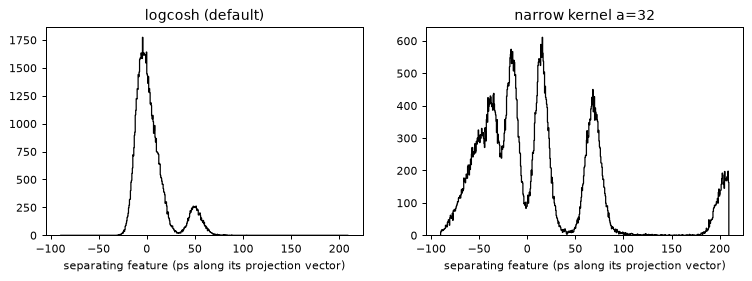

In [3]:
print(f"{'contrast':22s} {'negentropy':>10s} {'excess kurtosis':>16s}")
for name in ("logcosh (default)", "narrow kernel a=32"):
    s = separating_feature(fits[name])
    print(f"{name:22s} {negentropy(s):10.3f} {kurtosis(s):16.2f}")
fig, axs = plt.subplots(1, 2, figsize=(10, 3))
for ax, name in zip(axs, ("logcosh (default)", "narrow kernel a=32")):
    s = separating_feature(fits[name]); s = s - np.median(s)
    ax.hist(s, bins=np.arange(-90, 210, 0.5), histtype="step", color="k")
    ax.set_title(name); ax.set_xlabel("separating feature (ps along its projection vector)")

## 3. Comparison with an exact-negentropy search

In 2D, after whitening, ICA reduces to one rotation angle. Scanning it and maximizing the summed negentropy of
the two components (equivalently, minimizing their mutual information) gives the "exact" ICA solution to compare
against.

exact-negentropy rotation: mixing directions [15.9, 65.3]
narrow-kernel FastICA (a=32): (1, 65)


Text(0, 0.5, 'summed negentropy')

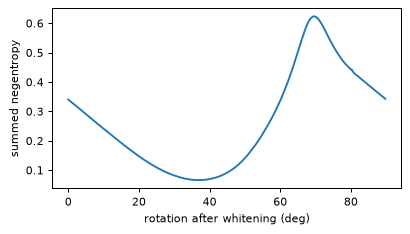

In [4]:
ev, E = np.linalg.eigh(np.cov(xc.T)); K = E @ np.diag(ev ** -0.5) @ E.T; Z = xc @ K
ths = np.radians(np.arange(0, 90, 0.25))
J = [negentropy(Z @ [np.cos(t), np.sin(t)]) + negentropy(Z @ [-np.sin(t), np.cos(t)]) for t in ths]
t = ths[int(np.argmax(J))]
W = K @ np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]]); A = np.linalg.inv(W)
print("exact-negentropy rotation: mixing directions", sorted(round(float(np.degrees(np.arctan2(A[j, 1], A[j, 0])) % 180), 1) for j in range(2)))
print("narrow-kernel FastICA (a=32):", mixing_dirs(fits["narrow kernel a=32"]))
plt.figure(figsize=(5, 2.6)); plt.plot(np.degrees(ths), J); plt.xlabel("rotation after whitening (deg)"); plt.ylabel("summed negentropy")